In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [6]:
df = pd.read_csv(r'/home/troy/Downloads/tchin-sindy-lotka-volterra/data/raw/lotka_volterra_data.csv')
df.head(10)

,time,prey_clean,predator_clean,prey_noisy,predator_noisy
0,0.000000,10.000000,5.000000,10.017443,4.942871
1,0.050125,8.185993,5.973748,8.181138,5.952272
2,0.100251,6.401845,6.817807,6.424590,6.817995
3,0.150376,4.823312,7.457845,4.876795,7.459528
4,0.200501,3.532764,7.874645,3.524541,7.858519
5,0.250627,2.548465,8.080227,2.540243,8.102544
6,0.300752,1.829989,8.114723,1.885445,8.076469
7,0.350877,1.315131,8.025883,1.342080,8.020782
8,0.401003,0.950473,7.851923,0.933987,7.856233
9,0.451128,0.694892,7.622369,0.713945,7.640802


In [7]:
columns = df.columns.tolist()
columns

['time', 'prey_clean', 'predator_clean', 'prey_noisy', 'predator_noisy']

In [8]:
df.isna().sum()
df.dropna()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   time            400 non-null    float64
 1   prey_clean      400 non-null    float64
 2   predator_clean  400 non-null    float64
 3   prey_noisy      400 non-null    float64
 4   predator_noisy  400 non-null    float64
dtypes: float64(5)
memory usage: 15.8 KB


In [9]:
# Split the data into training and testing sets
X = df.drop('prey_clean', axis=1)
y = df['predator_clean']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X.shape; y.shape

(400,)

In [10]:
X_train.shape; y_train.shape
X_test.shape; y_test.shape

(80,)

In [11]:
print(X_train); print(y_train)
print(X_test); print(y_test)

          time  predator_clean  prey_noisy  predator_noisy
3     0.150376        7.457845    4.876795        7.459528
18    0.902256        5.145240    0.045286        5.187495
202  10.125313        2.013915    0.051617        2.045073
250  12.531328        0.188021    0.035869        0.254270
274  13.734336        0.063928    0.390493        0.013496
..         ...             ...         ...             ...
71    3.558897        0.371805    0.087252        0.289327
106   5.313283        0.071958    0.403178        0.050733
270  13.533835        0.075260    0.369506        0.119908
348  17.443609        5.080080    0.050460        5.058169
102   5.112782        0.085330    0.241368        0.035219

[320 rows x 4 columns]
3      7.457845
18     5.145240
202    2.013915
250    0.188021
274    0.063928
         ...   
71     0.371805
106    0.071958
270    0.075260
348    5.080080
102    0.085330
Name: predator_clean, Length: 320, dtype: float64
          time  predator_clean  prey_noisy

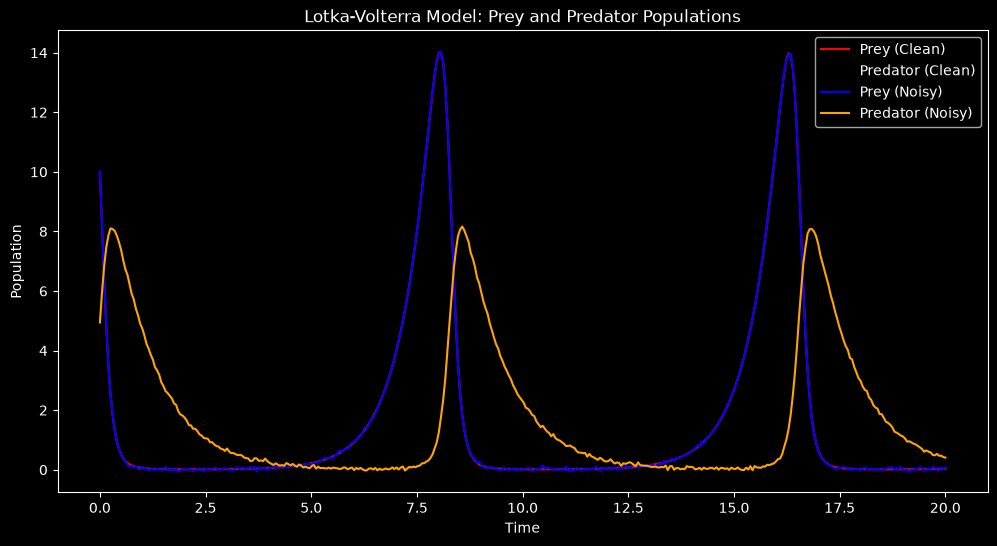

In [12]:
# Plot the training and test data
plt.style.use('dark_background')
plt.figure(figsize=(12, 6))
plt.plot(df['time'], df['prey_clean'], label='Prey (Clean)', color='red')
plt.plot(df['time'], df['predator_clean'], label='Predator (Clean)', color='black')
plt.plot(df['time'], df['prey_noisy'], label='Prey (Noisy)', color='blue')
plt.plot(df['time'], df['predator_noisy'], label='Predator (Noisy)', color='orange')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('Lotka-Volterra Model: Prey and Predator Populations')
plt.legend() 

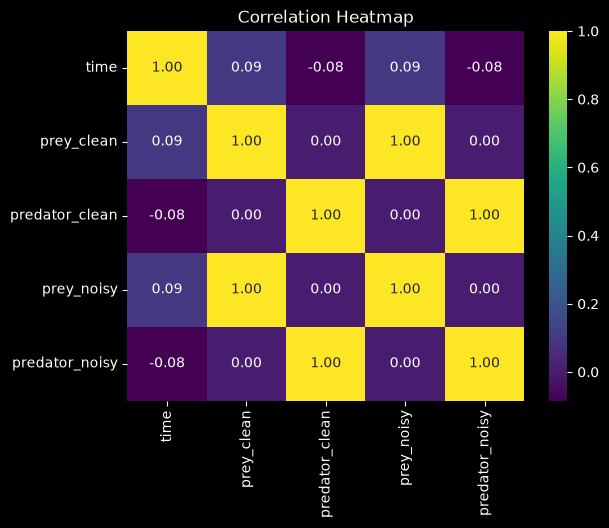

In [13]:
# Create a correlation heatmap
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='viridis', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [14]:
# Save cleaned data to a new CSV file
df.to_csv(r'/home/troy/Downloads/tchin-sindy-lotka-volterra/data/processed/lotka_volterra_data_cleaned.csv', index=False)   